# 🏀 March Madness · An Empirical Model Comparison
### SYDE 522 · Group 25 · Implementation notebook

**One task. Shared data. Fair comparisons.**

We predict the probability that **Team A wins an actual men's NCAA tournament game**, then compare logistic regression, an RBF SVM, a random forest, and a small multilayer perceptron (MLP).

> **Research questions**  
> 1. Do pre-tournament statistics improve predictions beyond seeds?  
> 2. Do more complex models consistently outperform simpler methods?

This notebook implements the analysis; results are computed from your files, never prefilled. It is an academic evaluation, so there is no competition-submission step.

---
## Start here

1. Keep this notebook beside the supplied `data/` folder. The KenPom pre-tournament CSV is already included.
2. The competition CSVs are already included. To replace or refresh them, sign in at [March Machine Learning Mania 2026 — Data](https://www.kaggle.com/competitions/march-machine-learning-mania-2026/data), review/accept the rules if prompted, download the files, and unzip them.
3. If refreshing the data, place `MNCAATourneyCompactResults.csv`, `MTeams.csv`, and preferably `MTeamSpellings.csv` in `data/competition/`. Nested folders are supported.
4. Select a Python 3.10+ kernel. Run the installation cell once if needed, then run the notebook from top to bottom.
5. Start in **quick** mode to check the pipeline. Switch to **full** for the report. Enable final testing only after reviewing and freezing the development setup.

**Status:** Real pre-tournament predictors and all three competition CSVs are included. Five verified team-name mappings are supplied. Run the notebook to compute model results.


## Workflow overview

| Phase | Steps | Deliverable |
|:--|:--|:--|
| **01 · Understand** | Load and audit data | Validated team-season records |
| **02 · Construct** | Map teams and build matchups | One row per game |
| **03 · Design** | Chronological splits and shared metrics | Reusable evaluation protocol |
| **04 · Model** | Baselines and four calibrated classifiers | Development comparison |
| **05 · Evaluate** | Locked testing, plots, error analysis | Reproducible evidence |

**Scope:** 2003–2025 men's tournament games; 2020 is excluded. First Four/play-in games are included. The final test seasons are 2023, 2024, and 2025.


---
## STEP 0 — Prepare the environment

Uncomment the `%pip` line only if imports fail. Restart the kernel after installation if requested. All models run on a CPU; no GPU is required.


In [23]:
# Uncomment and run once if your environment needs these packages:
# %pip install -r requirements.txt


In [24]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import platform
import re
import unicodedata
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, accuracy_score, confusion_matrix
from sklearn.exceptions import ConvergenceWarning

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")


Python 3.13.18 | pandas 2.2.3 | scikit-learn 1.6.1


### Experiment settings

- **Quick:** two validation seasons, two candidates per model, one repeat. A pipeline check, not the final study.
- **Full:** five validation seasons, four candidates per model, three repeats. The same candidate count is used for each method; run time will differ.
- `RUN_FINAL_TEST` defaults to `False` to keep the test results out of development decisions.

Run folders are timestamped so a new run does not overwrite old evidence.


In [25]:
# Edit this path only if the notebook is opened from a different working folder.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data/kenpom").exists():
    candidate = PROJECT_DIR / "output/march-madness"
    if (candidate / "data/kenpom").exists():
        PROJECT_DIR = candidate

DATA_DIR = PROJECT_DIR / "data"
MODE = "quick"                    # "quick" first; "full" for the report
RUN_FINAL_TEST = False             # change only after development decisions are frozen
MASTER_SEED = 522
START_YEAR, END_YEAR = 2003, 2025
TEST_YEARS = [2023, 2024, 2025]
CALIBRATION_SEASONS = 2
assert MODE in {"quick", "full"}
VALIDATION_YEARS = [2021, 2022] if MODE == "quick" else [2017, 2018, 2019, 2021, 2022]
RUN_SEEDS = [522] if MODE == "quick" else [522, 523, 524]
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + MODE
OUT = PROJECT_DIR / "results" / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)
FEATURE_SETS = {
    "Seeds only": ["Seed_diff"],
    "Seeds + stats": ["Seed_diff", "AdjOE_diff", "AdjDE_diff", "AdjTempo_diff"],
}
MODEL_NAMES = ["Logistic regression", "RBF SVM", "Random forest", "MLP"]
print("Project:", PROJECT_DIR)
print("Results:", OUT)
print("Mode:", MODE, "| Validation:", VALIDATION_YEARS, "| Repeats:", RUN_SEEDS)


Project: /content
Results: /content/results/20261118T193031943175Z_quick
Mode: quick | Validation: [2021, 2022] | Repeats: [522]


---
## STEP 1 — Load the source files

The KenPom source supplies **team-season predictors**. The competition source supplies **game-level outcomes**. These are different observation units and must be joined carefully.

The loader stops with a useful message if a file is missing or if multiple copies make the selection ambiguous. It does not download restricted files or access your Kaggle credentials.


In [26]:
def find_file(name, required=True):
    matches = sorted(DATA_DIR.rglob(name))
    if len(matches) > 1:
        raise ValueError(f"Multiple copies of {name}. Keep one under data/: {matches}")
    if not matches:
        if required:
            raise FileNotFoundError(
                f"Missing {name}. Download and unzip the competition data, then place it in "
                f"{DATA_DIR / 'competition'}. See Start here above."
            )
        return None
    return matches[0]

paths = {
    "kenpom": find_file("INT _ KenPom _ Summary (Pre-Tournament).csv"),
    "results": find_file("MNCAATourneyCompactResults.csv"),
    "teams": find_file("MTeams.csv"),
    "spellings": find_file("MTeamSpellings.csv", required=False),
}
kenpom_raw = pd.read_csv(paths["kenpom"])
results_raw = pd.read_csv(paths["results"])
teams = pd.read_csv(paths["teams"])
spellings = (pd.read_csv(paths["spellings"], encoding="latin-1")
             if paths["spellings"] else pd.DataFrame(columns=["TeamNameSpelling", "TeamID"]))
if paths["spellings"] is None:
    print("Optional MTeamSpellings.csv is absent: more manual team mappings may be needed.")
display(pd.DataFrame([
    {"source": key, "file": path.name, "bytes": path.stat().st_size}
    for key, path in paths.items() if path is not None
]))


,source,file,bytes
0,kenpom,INT _ KenPom _ Summary (Pre-Tournament).csv,821764
1,results,MNCAATourneyCompactResults.csv,77711
2,teams,MTeams.csv,10056
3,spellings,MTeamSpellings.csv,22792


---
## STEP 2 — Audit the data

We explicitly select pre-tournament predictors. We do **not** use post-season flags, scores from the game being predicted, or unverified fallback statistics.

Blank seeds among non-tournament teams are expected. Missing seeds among the teams in actual tournament games will trigger a check later.


,Season,TeamName,Seed,AdjOE,AdjDE,AdjTempo
0,2025,Abilene Christian,NaN,97.6324,102.0970,69.3532
1,2025,Air Force,NaN,98.9012,111.4670,64.3683
2,2025,Akron,13.0,113.6890,107.1090,71.3708
3,2025,Alabama,2.0,126.5110,96.5798,74.8553
4,2025,Alabama A&M,NaN,92.0141,115.5150,70.9783


,missing_count,missing_fraction
Seed,6162,0.8072
AdjOE,0,0.0000
AdjDE,0,0.0000
AdjTempo,0,0.0000


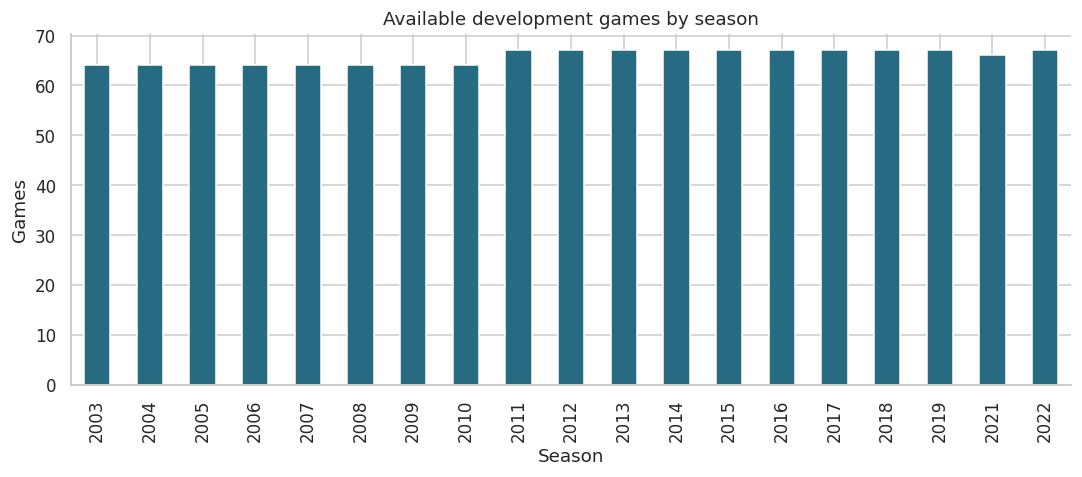

In [27]:
RAW_FEATURES = ["Seed", "AdjOE", "AdjDE", "AdjTempo"]
required_k = {"Season", "TeamName", *RAW_FEATURES}
required_r = {"Season", "DayNum", "WTeamID", "LTeamID"}
assert required_k <= set(kenpom_raw.columns), "KenPom columns do not match the expected schema."
assert required_r <= set(results_raw.columns), "Tournament result columns are missing."
assert {"TeamID", "TeamName"} <= set(teams.columns)

kenpom = kenpom_raw.loc[
    kenpom_raw.Season.between(START_YEAR, END_YEAR) & kenpom_raw.Season.ne(2020),
    ["Season", "TeamName", *RAW_FEATURES]
].copy()
games = results_raw.loc[
    results_raw.Season.between(START_YEAR, END_YEAR) & results_raw.Season.ne(2020)
].copy()
for col in RAW_FEATURES:
    kenpom[col] = pd.to_numeric(kenpom[col], errors="coerce")
assert not kenpom.duplicated(["Season", "TeamName"]).any(), "Duplicate team-season rows."
assert not games.duplicated(["Season", "DayNum", "WTeamID", "LTeamID"]).any(), "Duplicate games."
assert games.WTeamID.ne(games.LTeamID).all()
assert set(TEST_YEARS + VALIDATION_YEARS) <= set(games.Season), "Required evaluation seasons are missing."
assert set(games.Season) <= set(kenpom.Season), "Game seasons lack predictor coverage."

display(kenpom.head())
display(pd.DataFrame({"missing_count": kenpom[RAW_FEATURES].isna().sum(),
                      "missing_fraction": kenpom[RAW_FEATURES].isna().mean()}))
# Only development-season outcomes enter exploratory plots.
dev_counts = games.loc[games.Season.lt(min(TEST_YEARS))].groupby("Season").size()
fig, ax = plt.subplots()
dev_counts.plot.bar(ax=ax, color="#276B82")
ax.set(title="Available development games by season", ylabel="Games", xlabel="Season")
plt.tight_layout(); plt.show()


---
## STEP 3 — Match team names safely

Name spelling differs across sources. We normalize punctuation/case and use Kaggle's official spelling aliases. **No fuzzy match is silently accepted.**

If this cell reports unmatched participants, review `unmatched_teams.csv` in the displayed results folder. Add verified mappings below, for example `"KenPom spelling": 1234`, then rerun this step. Never guess an ID.

Aliases mapping to multiple IDs are excluded from automatic matching and require an explicit decision.


In [28]:
MANUAL_TEAM_IDS = {
    # Verified against MTeams/MTeamSpellings; Saint Francis is the PA team
    # (the NY team last appeared in Division I in 2023).
    "Saint Francis": 1384,
    "Mississippi Valley St.": 1290,
    "Southeast Missouri St.": 1369,
    "Texas A&M Corpus Chris": 1394,
    "Cal St. Bakersfield": 1167,
}

def normalize_name(value):
    s = unicodedata.normalize("NFKD", str(value)).encode("ascii", "ignore").decode()
    s = s.lower().replace("&", " and ")
    return re.sub(r"[^a-z0-9]", "", s)

alias_rows = teams[["TeamName", "TeamID"]].rename(columns={"TeamName": "Alias"})
if not spellings.empty:
    alias_rows = pd.concat([alias_rows, spellings[["TeamNameSpelling", "TeamID"]]
                            .rename(columns={"TeamNameSpelling": "Alias"})], ignore_index=True)
alias_rows["key"] = alias_rows.Alias.map(normalize_name)
counts = alias_rows.groupby("key").TeamID.nunique()
ambiguous_keys = set(counts[counts > 1].index)
alias_map = (alias_rows.loc[~alias_rows.key.isin(ambiguous_keys)]
             .drop_duplicates("key").set_index("key").TeamID.to_dict())
assert set(MANUAL_TEAM_IDS.values()) <= set(teams.TeamID), "A manual ID is absent from MTeams.csv."

mapped = kenpom.copy()
mapped["TeamID"] = mapped.TeamName.map(normalize_name).map(alias_map)
manual_ids = mapped.TeamName.map(MANUAL_TEAM_IDS)
mapped["TeamID"] = manual_ids.combine_first(mapped.TeamID)

# Report every seeded row that cannot be matched; do not silently discard it.
unmatched = mapped.loc[mapped.Seed.notna() & mapped.TeamID.isna(), ["Season", "TeamName", "Seed"]]
if not unmatched.empty:
    unmatched.to_csv(OUT / "unmatched_teams.csv", index=False)
    display(unmatched.head(30))
    raise ValueError("Unmatched seeded teams. Review the export and add verified MANUAL_TEAM_IDS.")

mapped = mapped.dropna(subset=["TeamID"]).copy()
mapped["TeamID"] = mapped.TeamID.astype(int)
assert not mapped.duplicated(["Season", "TeamID"]).any(), "Multiple KenPom teams map to one ID in a season."
mapped[["Season", "TeamName", "TeamID"]].to_csv(OUT / "team_mapping.csv", index=False)
print(f"Mapped {len(mapped):,} team-season rows; {len(ambiguous_keys)} ambiguous normalized aliases were excluded.")


Mapped 7,613 team-season rows; 0 ambiguous normalized aliases were excluded.


---
## STEP 4 — Construct the shared matchup table

**Team A = lower team ID; Team B = higher team ID.** This ordering does not depend on who won.

For each statistic, compute `Team A − Team B`. Lower seed and lower defensive efficiency generally indicate stronger teams; the models learn the direction from training data.

We retain IDs and seasons for auditing, but use only the explicit difference columns as model inputs. Each game is counted once.


In [29]:
matchups = games[["Season", "DayNum", "WTeamID", "LTeamID"]].copy()
matchups["TeamA"] = np.minimum(matchups.WTeamID, matchups.LTeamID)
matchups["TeamB"] = np.maximum(matchups.WTeamID, matchups.LTeamID)
matchups["y_true"] = (matchups.WTeamID == matchups.TeamA).astype(int)
matchups["game_id"] = matchups.apply(
    lambda r: f"{int(r.Season)}_{int(r.DayNum)}_{int(r.TeamA)}_{int(r.TeamB)}", axis=1)
matchups = matchups.drop(columns=["WTeamID", "LTeamID"])
for side in ["A", "B"]:
    table = mapped[["Season", "TeamID", "TeamName", *RAW_FEATURES]].rename(
        columns={"TeamID": f"Team{side}", "TeamName": f"Name{side}",
                 **{c: f"{c}_{side}" for c in RAW_FEATURES}})
    matchups = matchups.merge(table, on=["Season", f"Team{side}"], how="left", validate="many_to_one")

missing_sides = matchups[["NameA", "NameB", "Seed_A", "Seed_B"]].isna().any(axis=1)
if missing_sides.any():
    matchups.loc[missing_sides].to_csv(OUT / "missing_matchup_features.csv", index=False)
    raise ValueError("Some games lack mapped teams or seeds. See missing_matchup_features.csv; fix before modeling.")
for side in ["A", "B"]:
    assert matchups[f"Seed_{side}"].between(1, 16).all(), "Unexpected seed range."
for c in RAW_FEATURES:
    matchups[f"{c}_diff"] = matchups[f"{c}_A"] - matchups[f"{c}_B"]
matchups = matchups.sort_values(["Season", "DayNum", "TeamA", "TeamB"]).reset_index(drop=True)
assert matchups.game_id.is_unique
assert len(matchups) == len(games), "Joining changed the number of games."
assert matchups.TeamA.lt(matchups.TeamB).all()
assert set(matchups.y_true) == {0, 1}
all_features = FEATURE_SETS["Seeds + stats"]
assert not np.isinf(matchups[all_features].to_numpy()).any()
matchups.to_csv(OUT / "matchups.csv", index=False)

development = matchups.loc[matchups.Season.lt(min(TEST_YEARS))].copy()
display(development[["Season", "NameA", "NameB", *all_features, "y_true"]].head())
print(f"{len(matchups):,} actual games; {len(development):,} development games. No games silently dropped.")


,Season,NameA,NameB,Seed_diff,AdjOE_diff,AdjDE_diff,AdjTempo_diff,y_true
0,2003,Texas Southern,UNC Asheville,0.0,-2.237,-5.8660,0.3680,0
1,2003,Arizona,Vermont,-15.0,13.588,-10.9991,8.7153,1
2,2003,Arizona St.,Memphis,3.0,1.812,2.8983,-1.4671,1
3,2003,BYU,Connecticut,7.0,-1.193,-1.0058,-5.4455,0
4,2003,Central Michigan,Creighton,5.0,-3.163,4.7823,3.5001,1


1,449 actual games; 1,248 development games. No games silently dropped.


### Development-only feature check

Inspect missingness and correlations before fixing the experiment. Do not choose features based on the held-out test outcomes. Median imputation is fitted within each training partition, never on the full table.


,count,mean,std,min,25%,50%,75%,max
Seed_diff,1248.0,0.0465,7.5009,-15.0000,-5.0000,0.0000,5.2500,15.0000
AdjOE_diff,1248.0,0.2891,8.5082,-27.4739,-4.9885,0.3520,5.5725,25.7764
AdjDE_diff,1248.0,0.3449,7.2896,-24.4589,-4.3351,0.3310,4.6214,23.1898
AdjTempo_diff,1248.0,0.3625,4.2764,-19.1009,-2.3848,0.3538,3.2124,14.1304


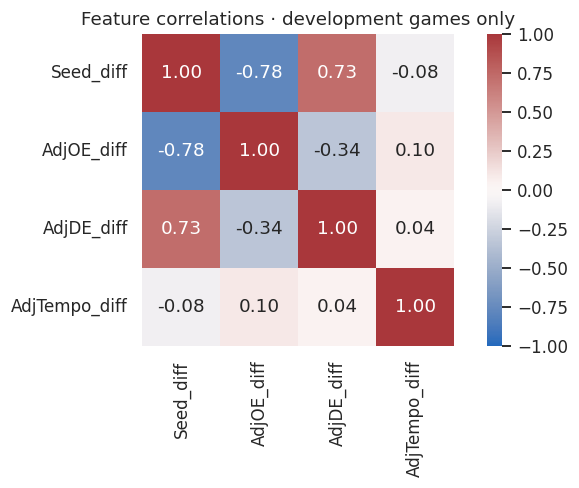

In [30]:
display(development[all_features].describe().T)
fig, ax = plt.subplots(figsize=(6.8, 4.6))
sns.heatmap(development[all_features].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Feature correlations · development games only")
plt.tight_layout(); plt.show()


---
## STEP 5 — Define chronological training, calibration, and validation

Every model uses the **same two most recent available training seasons for sigmoid probability calibration**. Earlier seasons fit the base estimator and its preprocessing. This gives the SVM valid probability estimates without hidden random calibration folds and keeps the comparison consistent across methods.

Example: validation in 2017 uses base training through 2014 and calibration in 2015–2016. Final testing uses base training through 2019 and calibration in 2021–2022 (there is no 2020 tournament).

Calibration consumes some data that could otherwise train the base model. This is a deliberate, shared design choice. This notebook compares calibrated pipelines, not uncalibrated classifiers.


In [31]:
def chronological_parts(history):
    seasons = sorted(history.Season.unique())
    if len(seasons) <= CALIBRATION_SEASONS:
        raise ValueError("Insufficient historical seasons for base training plus calibration.")
    cal_years = seasons[-CALIBRATION_SEASONS:]
    base = history.loc[~history.Season.isin(cal_years)].copy()
    cal = history.loc[history.Season.isin(cal_years)].copy()
    assert base.Season.max() < cal.Season.min()
    assert base.y_true.nunique() == cal.y_true.nunique() == 2
    return base, cal

split_rows = []
for year in VALIDATION_YEARS:
    history = development.loc[development.Season.lt(year)]
    base, cal = chronological_parts(history)
    valid = development.loc[development.Season.eq(year)]
    assert cal.Season.max() < year
    assert set(history.game_id).isdisjoint(valid.game_id)
    split_rows.append({"validation_season": year,
                       "base_years": f"{base.Season.min()}–{base.Season.max()}",
                       "calibration_years": ", ".join(map(str, sorted(cal.Season.unique()))),
                       "base_games": len(base), "calibration_games": len(cal),
                       "validation_games": len(valid)})
splits = pd.DataFrame(split_rows)
display(splits)
splits.to_csv(OUT / "validation_splits.csv", index=False)


,validation_season,base_years,calibration_years,base_games,calibration_games,validation_games
0,2021,2003–2017,"2018, 2019",981,134,66
1,2022,2003–2018,"2019, 2021",1048,133,67


---
## STEP 6 — Define one evaluation contract

| Metric | Interpretation | Preferred direction |
|:--|:--|:--|
| **Log loss · primary** | Probability quality; penalizes confident mistakes | Lower |
| **Brier score** | Mean squared probability error, on the binary 0–1 scale | Lower |
| **Accuracy** | Correct winner predictions at a 0.5 threshold | Higher |

For outcome $y_i\in\{0,1\}$ and predicted win probability $p_i$:

$$\mathrm{LogLoss}=-\frac{1}{N}\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]$$
$$\mathrm{Brier}=\frac{1}{N}\sum_i(p_i-y_i)^2$$

Threshold ties (`p = 0.5`) choose Team A. Probabilities are clipped only for numerical stability. Model selection uses the **equal-season average validation log loss**, averaged over the same recorded run seeds.


In [32]:
EPS = 1e-15

def evaluate(y, p):
    y, p = np.asarray(y), np.asarray(p, dtype=float)
    assert y.shape == p.shape and len(y) > 0
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return {"log_loss": float(log_loss(y, np.clip(p, EPS, 1-EPS), labels=[0, 1])),
            "brier": float(np.mean((p-y)**2)),
            "accuracy": float(accuracy_score(y, p >= 0.5))}

def seed_pick_accuracy(frame):
    # Equal seeds use the same Team-A tie convention.
    pick_a = frame.Seed_A.le(frame.Seed_B).astype(int)
    return float(accuracy_score(frame.y_true, pick_a))

def prediction_rows(frame, p, model, feature_set, run_seed, candidate_id=None):
    result = frame[["Season", "game_id", "NameA", "NameB", "Seed_A", "Seed_B", "y_true"]].copy()
    result = result.rename(columns={"Season": "season"})
    result["model"], result["feature_set"] = model, feature_set
    result["run_seed"], result["candidate_id"] = run_seed, candidate_id
    result["p_A_wins"] = p
    return result

# A deterministic seed pick is evaluated on accuracy only.
# For log loss and Brier, seed-only logistic regression is the probability baseline.
display(pd.DataFrame([{ "season": y, "better_seed_accuracy": seed_pick_accuracy(
    development.loc[development.Season.eq(y)])} for y in VALIDATION_YEARS]))


,season,better_seed_accuracy
0,2021,0.6667
1,2022,0.6567


---
## STEP 7 — Build the four model pipelines

Each model receives identical features and partitions. Logistic regression, SVM, and MLP receive standardized inputs; the forest does not need scaling. Imputation always learns from base-training rows only.

The MLP is deliberately small. We use regularization and a fixed iteration cap, with validation-based parameter selection. Automatic random early-stopping splits are disabled to keep this notebook's time-based protocol explicit. Convergence warnings are recorded for review.


In [33]:
CANDIDATES = {
    "Logistic regression": [{"C": c} for c in [0.1, 1.0, 0.01, 10.0]],
    "RBF SVM": [{"C": 0.5, "gamma": "scale"}, {"C": 2.0, "gamma": "scale"},
                {"C": 0.5, "gamma": 0.1}, {"C": 2.0, "gamma": 0.1}],
    "Random forest": [{"max_depth": d, "min_samples_leaf": l}
                      for d, l in [(3, 10), (None, 10), (3, 5), (None, 5)]],
    "MLP": [{"hidden_layer_sizes": h, "alpha": a}
            for h, a in [((8,), 0.1), ((16,), 0.1), ((8,), 1.0), ((16,), 1.0)]],
}
if MODE == "quick":
    CANDIDATES = {k: v[:2] for k, v in CANDIDATES.items()}

def make_base_model(name, params, seed):
    if name == "Logistic regression":
        estimator = LogisticRegression(max_iter=1500, random_state=seed, **params)
    elif name == "RBF SVM":
        estimator = SVC(kernel="rbf", probability=False, random_state=seed, **params)
    elif name == "Random forest":
        estimator = RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=seed, **params)
    elif name == "MLP":
        estimator = MLPClassifier(max_iter=600, solver="adam", learning_rate_init=0.001,
                                  early_stopping=False, random_state=seed, **params)
    else:
        raise ValueError(name)
    steps = [("impute", SimpleImputer(strategy="median", keep_empty_features=True))]
    if name != "Random forest":
        steps.append(("scale", StandardScaler()))
    return Pipeline(steps + [("model", estimator)])

def fit_calibrated(history, columns, name, params, seed):
    base, cal = chronological_parts(history)
    if base[columns].isna().all().any():
        raise ValueError("An entire base-training predictor is missing; inspect data rather than filling it blindly.")
    model = make_base_model(name, params, seed)
    started = perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(base[columns], base.y_true)
        calibrated = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid")
        calibrated.fit(cal[columns], cal.y_true)
    notes = " | ".join(sorted({str(w.message) for w in caught}))
    return calibrated, perf_counter()-started, notes

display(pd.DataFrame([{"model": m, "candidates": len(CANDIDATES[m]),
                       "validation_seasons": len(VALIDATION_YEARS), "repeats": len(RUN_SEEDS)}
                      for m in MODEL_NAMES]))


,model,candidates,validation_seasons,repeats
0,Logistic regression,2,2,1
1,RBF SVM,2,2,1
2,Random forest,2,2,1
3,MLP,2,2,1


---
## STEP 8 — Tune using development seasons only

We test both **seeds only** and **seeds + statistics** for every model. This separates the value of additional information from the value of algorithm choice.

This is the main computation cell. Progress is printed after each model/feature-set pair. No final-test outcomes are scored here.


In [34]:
cv_scores, cv_predictions = [], []
for feature_set, columns in FEATURE_SETS.items():
    for name in MODEL_NAMES:
        for candidate_id, params in enumerate(CANDIDATES[name]):
            for seed in RUN_SEEDS:
                for year in VALIDATION_YEARS:
                    history = development.loc[development.Season.lt(year)]
                    valid = development.loc[development.Season.eq(year)]
                    fitted, seconds, notes = fit_calibrated(history, columns, name, params, seed)
                    p = fitted.predict_proba(valid[columns])[:, list(fitted.classes_).index(1)]
                    cv_scores.append({"model": name, "feature_set": feature_set,
                        "candidate_id": candidate_id, "run_seed": seed, "season": year,
                        "fit_seconds": seconds, "warnings": notes, **evaluate(valid.y_true, p)})
                    cv_predictions.append(prediction_rows(valid, p, name, feature_set, seed, candidate_id))
        print(f"Completed: {name} · {feature_set}")
cv_scores = pd.DataFrame(cv_scores)
cv_predictions = pd.concat(cv_predictions, ignore_index=True)
cv_scores.to_csv(OUT / "development_scores.csv", index=False)
cv_predictions.to_csv(OUT / "development_predictions.csv", index=False)

candidate_scores = (cv_scores.groupby(["model", "feature_set", "candidate_id"], as_index=False)
                    .agg(mean_log_loss=("log_loss", "mean"), mean_brier=("brier", "mean"),
                         mean_accuracy=("accuracy", "mean"), mean_fit_seconds=("fit_seconds", "mean")))
selected = (candidate_scores.sort_values(["mean_log_loss", "candidate_id"])
            .drop_duplicates(["model", "feature_set"]).reset_index(drop=True))
selected["parameters"] = selected.apply(
    lambda r: json.dumps(CANDIDATES[r.model][int(r.candidate_id)]), axis=1)
selected.to_csv(OUT / "selected_parameters.csv", index=False)
display(selected.sort_values(["feature_set", "mean_log_loss"]).round(4))
warning_rows = cv_scores.loc[cv_scores.warnings.ne("")]
print(f"Fits with recorded warnings: {len(warning_rows)} / {len(cv_scores)}")
if not warning_rows.empty:
    display(warning_rows[["model", "feature_set", "season", "warnings"]].head())


Completed: Logistic regression · Seeds only
Completed: RBF SVM · Seeds only
Completed: Random forest · Seeds only
Completed: MLP · Seeds only
Completed: Logistic regression · Seeds + stats
Completed: RBF SVM · Seeds + stats
Completed: Random forest · Seeds + stats
Completed: MLP · Seeds + stats


,model,feature_set,candidate_id,mean_log_loss,mean_brier,mean_accuracy,mean_fit_seconds,parameters
0,Logistic regression,Seeds + stats,1,0.6200,0.2171,0.6843,0.0320,"{""C"": 1.0}"
1,Random forest,Seeds + stats,1,0.6247,0.2155,0.6692,0.6402,"{""max_depth"": null, ""min_samples_leaf"": 10}"
4,MLP,Seeds + stats,1,0.6311,0.2198,0.6919,0.2984,"{""hidden_layer_sizes"": [16], ""alpha"": 0.1}"
7,RBF SVM,Seeds + stats,0,0.6481,0.2261,0.6692,0.0947,"{""C"": 0.5, ""gamma"": ""scale""}"
2,Logistic regression,Seeds only,1,0.6262,0.2188,0.6693,0.0355,"{""C"": 1.0}"
3,MLP,Seeds only,1,0.6308,0.2203,0.6693,0.1980,"{""hidden_layer_sizes"": [16], ""alpha"": 0.1}"
5,Random forest,Seeds only,0,0.6315,0.2206,0.6693,0.4662,"{""max_depth"": 3, ""min_samples_leaf"": 10}"
6,RBF SVM,Seeds only,0,0.6356,0.2218,0.6693,0.1238,"{""C"": 0.5, ""gamma"": ""scale""}"


Fits with recorded warnings: 0 / 32


### Development comparison · not a final generalization estimate

The same development folds were used to select settings, so these scores can be optimistic. The held-out test is reserved for the final comparison. Shorter bars are better for log loss.


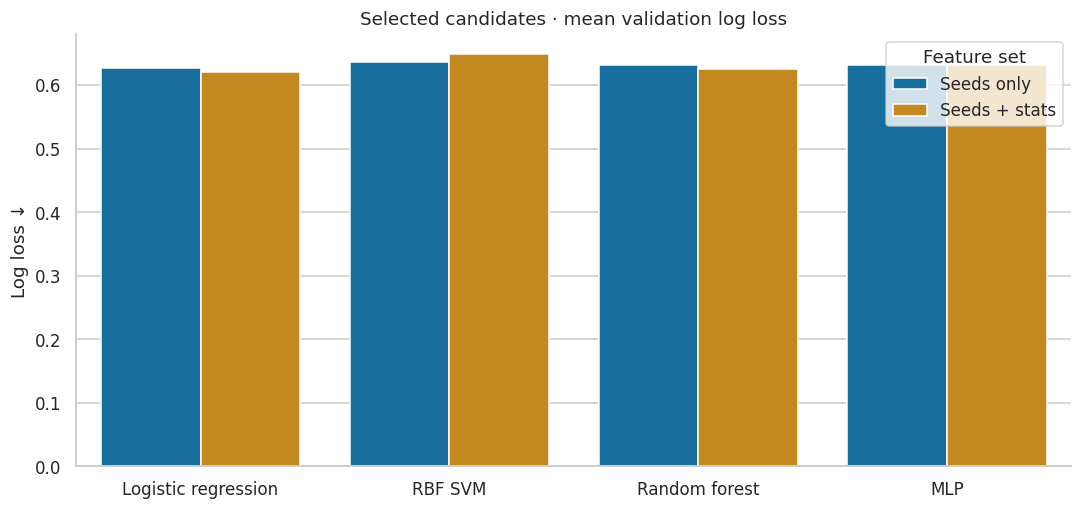

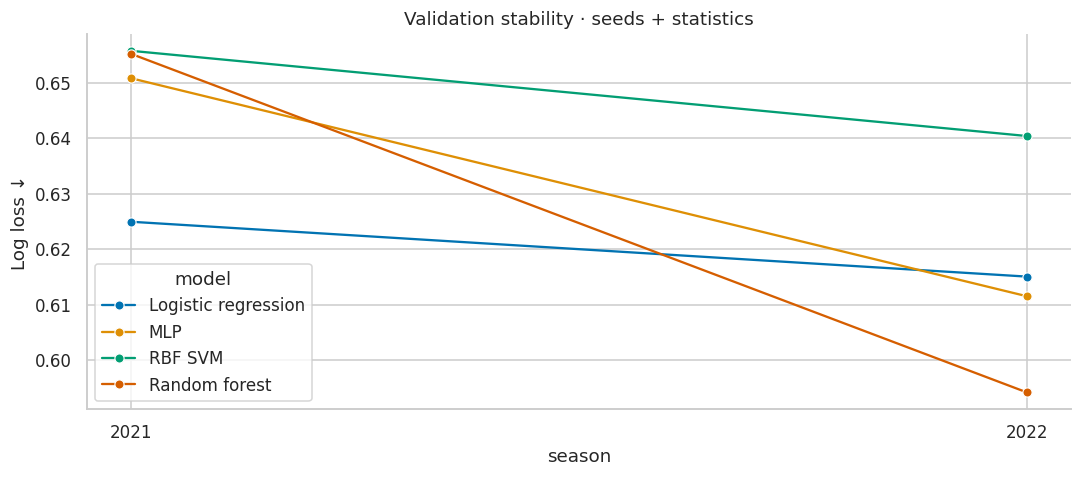

In [35]:
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=selected, x="model", y="mean_log_loss", hue="feature_set", order=MODEL_NAMES, hue_order=list(FEATURE_SETS), ax=ax)
ax.set(title="Selected candidates · mean validation log loss", xlabel="", ylabel="Log loss ↓")
ax.legend(title="Feature set", loc="best")
plt.tight_layout(); fig.savefig(OUT / "development_comparison.png", bbox_inches="tight"); plt.show()

chosen_dev = cv_scores.merge(selected[["model", "feature_set", "candidate_id"]],
                            on=["model", "feature_set", "candidate_id"], validate="many_to_one")
season_dev = chosen_dev.groupby(["season", "model", "feature_set"], as_index=False).log_loss.mean()
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=season_dev.loc[season_dev.feature_set.eq("Seeds + stats")],
             x="season", y="log_loss", hue="model", marker="o", ax=ax)
ax.set(title="Validation stability · seeds + statistics", ylabel="Log loss ↓")
ax.set_xticks(VALIDATION_YEARS)
plt.tight_layout(); plt.show()


---
## STEP 9 — Freeze the protocol and unlock final testing

Before setting `RUN_FINAL_TEST = True` in the settings cell:

- Use **full** mode for the report.
- Resolve missing-data and convergence concerns using development data.
- Freeze the features, candidate grids, calibration rule, and random seeds.
- Agree that test results will be reported, not used to retune the models.

The manifest below records input-file hashes, package versions, configuration, and selected settings. Final fitting uses history through 2022, partitioned into base training and calibration as described above. It then scores 2023–2025 with no updating between test seasons.


In [36]:
def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

manifest = {
    "run_id": RUN_ID, "mode": MODE, "final_test_enabled": RUN_FINAL_TEST,
    "years": [START_YEAR, END_YEAR], "validation_years": VALIDATION_YEARS,
    "test_years": TEST_YEARS, "calibration_seasons": CALIBRATION_SEASONS,
    "run_seeds": RUN_SEEDS, "features": FEATURE_SETS,
    "manual_team_ids": MANUAL_TEAM_IDS,
    "packages": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "sklearn": sklearn.__version__},
    "inputs": {k: {"filename": p.name, "sha256": sha256(p)} for k, p in paths.items() if p},
    "selected": selected.to_dict(orient="records"),
    "candidate_grids": CANDIDATES,
}
(OUT / "experiment_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Manifest saved.")
if not RUN_FINAL_TEST:
    display(Markdown("> **Final test is locked.** Development results are ready. "
                     "After freezing your choices, enable RUN_FINAL_TEST and rerun from the settings cell."))
elif MODE != "full":
    display(Markdown("> **Quick-mode test:** useful for debugging only. Do not report it as the full study."))


Manifest saved.


> **Final test is locked.** Development results are ready. After freezing your choices, enable RUN_FINAL_TEST and rerun from the settings cell.

In [37]:
final_predictions = pd.DataFrame()
final_fit_records = []
if RUN_FINAL_TEST:
    test = matchups.loc[matchups.Season.isin(TEST_YEARS)].copy()
    assert development.Season.max() < test.Season.min()
    assert set(development.game_id).isdisjoint(test.game_id)
    saved_predictions = []
    for row in selected.itertuples(index=False):
        params = CANDIDATES[row.model][int(row.candidate_id)]
        columns = FEATURE_SETS[row.feature_set]
        for seed in RUN_SEEDS:
            fitted, seconds, notes = fit_calibrated(development, columns, row.model, params, seed)
            p = fitted.predict_proba(test[columns])[:, list(fitted.classes_).index(1)]
            saved_predictions.append(prediction_rows(test, p, row.model, row.feature_set, seed))
            final_fit_records.append({"model": row.model, "feature_set": row.feature_set,
                                      "run_seed": seed, "fit_seconds": seconds, "warnings": notes})
    final_predictions = pd.concat(saved_predictions, ignore_index=True)
    final_predictions.to_csv(OUT / "test_predictions.csv", index=False)
    pd.DataFrame(final_fit_records).to_csv(OUT / "final_fit_records.csv", index=False)
    print(f"Saved {len(final_predictions):,} predictions across all model/feature/run combinations.")


---
## STEP 10 — Compare held-out performance

**Pooled scores** weight each game equally. **Season scores** reveal whether a result is consistent across tournaments. Repeated runs are summarized as mean ± standard deviation; they are not treated as additional independent games.

The better-seed rule is shown separately because its hard picks are not calibrated win probabilities.


In [38]:
if RUN_FINAL_TEST:
    pooled_records, season_records = [], []
    for (name, feature_set, seed), group in final_predictions.groupby(["model", "feature_set", "run_seed"]):
        pooled_records.append({"model": name, "feature_set": feature_set, "run_seed": seed,
                               **evaluate(group.y_true, group.p_A_wins)})
        for year, season_group in group.groupby("season"):
            season_records.append({"model": name, "feature_set": feature_set,
                                   "run_seed": seed, "season": year,
                                   **evaluate(season_group.y_true, season_group.p_A_wins)})
    pooled_scores = pd.DataFrame(pooled_records)
    season_scores = pd.DataFrame(season_records)
    summary = pooled_scores.groupby(["model", "feature_set"]).agg(
        log_loss_mean=("log_loss", "mean"), log_loss_sd=("log_loss", "std"),
        brier_mean=("brier", "mean"), brier_sd=("brier", "std"),
        accuracy_mean=("accuracy", "mean"), accuracy_sd=("accuracy", "std"))
    display(summary.round(4))  # NaN SD in quick mode means only one run, not zero uncertainty.
    pooled_scores.to_csv(OUT / "test_pooled_scores.csv", index=False)
    season_scores.to_csv(OUT / "test_season_scores.csv", index=False)
    summary.to_csv(OUT / "test_summary.csv")
    seed_baseline = pd.DataFrame([{"season": y, "accuracy": seed_pick_accuracy(test.loc[test.Season.eq(y)])}
                                  for y in TEST_YEARS])
    display(seed_baseline)
    print("Better-seed pooled accuracy:", round(seed_pick_accuracy(test), 4))
    seed_baseline.to_csv(OUT / "better_seed_baseline.csv", index=False)

    # Paired season differences: positive improvement means lower loss with statistics.
    feature_effect = season_scores.pivot(index=["model", "run_seed", "season"],
                                         columns="feature_set", values="log_loss")
    feature_effect["improvement_with_stats"] = feature_effect["Seeds only"] - feature_effect["Seeds + stats"]
    display(feature_effect.groupby("model").improvement_with_stats.agg(["mean", "min", "max"]))
    feature_effect.to_csv(OUT / "feature_set_comparison.csv")
else:
    print("Final comparison will appear after final testing is enabled.")


Final comparison will appear after final testing is enabled.


### Visual comparison

Error bars show variability across random initializations, **not confidence intervals for future tournaments**. With only three test seasons, claims of statistical superiority should remain cautious.


In [39]:
if RUN_FINAL_TEST:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for ax, metric, title in zip(axes, ["log_loss", "brier", "accuracy"],
                                 ["Log loss ↓", "Brier score ↓", "Accuracy ↑"]):
        sns.barplot(data=pooled_scores, x="model", y=metric, hue="feature_set",
                    errorbar="sd", order=MODEL_NAMES, hue_order=list(FEATURE_SETS), ax=ax)
        ax.set(title=title, xlabel="", ylabel="")
        ax.tick_params(axis="x", rotation=25)
    handles, labels = axes[0].get_legend_handles_labels()
    for ax in axes:
        ax.get_legend().remove()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False)
    fig.suptitle("Held-out games · 2023–2025", y=1.10, fontweight="bold")
    plt.tight_layout(); fig.savefig(OUT / "test_metrics.png", bbox_inches="tight"); plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.lineplot(data=season_scores.loc[season_scores.feature_set.eq("Seeds + stats")],
                 x="season", y="log_loss", hue="model", marker="o", errorbar="sd", ax=ax)
    ax.set(title="Does performance hold across seasons?", ylabel="Log loss ↓")
    ax.set_xticks(TEST_YEARS)
    plt.tight_layout(); fig.savefig(OUT / "test_by_season.png", bbox_inches="tight"); plt.show()


### Calibration and confident mistakes

For clarity, these diagnostic plots use the **first prespecified run seed**, rather than averaging probabilities into a new ensemble. A calibration curve near the diagonal suggests predicted confidence matches observed frequencies; small bins are noisy.

The model inspected for errors is selected by development log loss, not by test performance.


In [40]:
if RUN_FINAL_TEST:
    primary = final_predictions.loc[
        final_predictions.run_seed.eq(RUN_SEEDS[0]) & final_predictions.feature_set.eq("Seeds + stats")]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
    for name, group in primary.groupby("model"):
        observed, predicted = calibration_curve(group.y_true, group.p_A_wins, n_bins=5, strategy="quantile")
        axes[0].plot(predicted, observed, marker="o", label=name)
        axes[1].hist(group.p_A_wins, bins=np.linspace(0, 1, 11), histtype="step", linewidth=2, label=name)
    axes[0].set(title="Calibration · first prespecified run", xlabel="Predicted P(A wins)", ylabel="Observed A-win frequency")
    axes[1].set(title="Prediction confidence", xlabel="Predicted P(A wins)", ylabel="Games")
    axes[0].legend(fontsize=8)
    plt.tight_layout(); fig.savefig(OUT / "calibration.png", bbox_inches="tight"); plt.show()

    focus_name = selected.loc[selected.feature_set.eq("Seeds + stats")].sort_values("mean_log_loss").iloc[0].model
    errors = primary.loc[primary.model.eq(focus_name)].copy()
    errors["predicted_A_win"] = (errors.p_A_wins >= 0.5).astype(int)
    errors["confidence"] = np.maximum(errors.p_A_wins, 1-errors.p_A_wins)
    errors["wrong"] = errors.predicted_A_win.ne(errors.y_true)
    errors["equal_seeds"] = errors.Seed_A.eq(errors.Seed_B)
    errors["actual_upset"] = ((errors.y_true.eq(1) & errors.Seed_A.gt(errors.Seed_B)) |
                               (errors.y_true.eq(0) & errors.Seed_B.gt(errors.Seed_A)))
    display(Markdown(f"**Development-selected model:** {focus_name}"))
    display(errors.loc[errors.wrong].sort_values("confidence", ascending=False)[
        ["season", "NameA", "NameB", "Seed_A", "Seed_B", "y_true", "p_A_wins", "actual_upset"]].head(10))
    errors.to_csv(OUT / "error_analysis.csv", index=False)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    sns.heatmap(confusion_matrix(errors.y_true, errors.predicted_A_win, labels=[0, 1]),
                annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["B wins", "A wins"], yticklabels=["B wins", "A wins"], ax=ax)
    ax.set(title=focus_name, xlabel="Predicted", ylabel="Actual")
    plt.tight_layout(); plt.show()


---
## STEP 11 — Interpret and report

Fill in these conclusions **after** running the full experiment:

| Question | Evidence to report |
|:--|:--|
| Do statistics help? | Within-model change in held-out log loss from adding statistics, overall and by season |
| Does complexity help? | Four-model comparison using the same full feature set |
| Are probabilities useful? | Log loss, Brier score, calibration curves, and confident mistakes |
| Are results stable? | Differences across test seasons and run seeds |
| What are the limitations? | Small tournament sample, correlated games, source timing, name mapping, calibration data cost |

**Reporting rules**

- Identify the development-selected settings and state the tuning budget.
- Report unfavorable results as well as favorable ones. A complex model need not win.
- Do not claim causality from predictive importance or significance from a small score difference.
- Note that repeated seeds measure training variability, not additional independent tournaments.
- Treat this as an empirical comparison inspired by prior work, not an exact replication of a paper unless its complete protocol was reproduced.
- Keep final-test data out of model revision. If you revise after seeing it, disclose that it became development data.

### Saved evidence

Each `results/<run_id>/` folder contains the experiment manifest, team mappings, matchup table, validation splits, candidate scores, selected settings, and development predictions. Once testing is unlocked it also contains test predictions, scores, plots, and error analysis.

### Sources and design references

- [KenPom dataset on Kaggle](https://www.kaggle.com/datasets/jonathanpilafas/2024-march-madness-statistical-analysis) — included pre-tournament file from version 31, retrieved November 18, 2026. The file's pre-tournament designation is the source's; independently verify provenance if required by the course.
- [March Machine Learning Mania 2026](https://www.kaggle.com/competitions/march-machine-learning-mania-2026/data) — tournament outcomes and team identifiers, supplied by the user on November 18, 2026.
- [Beginner Workflow by melccoro](https://www.kaggle.com/code/melccoro/ncaa-march-madness-beginner-workflow) — inspiration for the step-by-step presentation; this implementation and comparison design are specific to our project.
- [Scikit-learn metrics](https://scikit-learn.org/stable/modules/model_evaluation.html) and [probability calibration](https://scikit-learn.org/stable/modules/calibration.html).
- Group 25 milestone report — project scope and proposed model families.
